# Langevin Dynamics - Ланжевеновская динамика

### Что такое динамика Ланжевена? 

Согласно Википедии, «в физике, динамика Ланжевена - это подход к математическому моделированию динамики молекулярных систем. Первоначально она была разработана французским физиком Полом Ланжевином. Этот подход характеризуется использованием упрощенных моделей при рассмотрении выделенных степеней свободы с помощью использования стохастических уравнений». https://en.wikipedia.org/wiki/Langevin_dynamics

Например, допустим, мы хотим имитировать какой-то белок таким образом, чтобы охватить то, как он движется в своей нативной водной среде, но не заинтересованы в детальном анализе, как движутся молекулы воды. Одним из подходов было бы непосредственно моделировать большое количество молекул воды, взаимодействующих с белком. Это часто используемый подход, но он требует от нас значительное количество вычислительных ресурсов, имитирующих движения отдельных молекул воды, которые нас не интересуют. Что если бы мы могли взять систему, и приблизительно рассмотреть эффекты ее взаимодействия с водой без необходимости явно имитировать тысячи молекул воды? Тут и возникает ланжевеновская динамика!

Давайте сначала посмотрим на математику, управляющая динамикой Ланжевена, а затем мы попробуем применить ее. Вспоминаем второй закон Ньютона:
$$F = ma$$
или, поскольку ускорение является второй производной координаты от времени ($M$ - массив, который хранит все массы частиц в нашей системе и $X$ вектор всех положений всех частиц в нашей системе):
$$F = M\ddot{X}$$
Теперь мы можем посмотреть на уравнение Ланжевена:
$$M\ddot{X} = -\nabla U(X) - \gamma\dot{X} + \sqrt{2\gamma k_{B}T}R(t)$$

Хорошо, это был, вероятно, большой прыжок! Но давайте посмотрим на каждое слагаемое отдельно. Слева - это всего лишь полная сила в системе, как уже сказал нам Ньютон, так что это должно означать, что все справа просто добавляется к общей силе в нашей системе. Если вы помните закон Гука, описывающий силу, оказываемую пружиной:
$$F = -kx$$
где _k_ - постоянная жесткости и _x_ расстояние, на которое пружина растянута или сжата, а также вспомним сопутствующий закон о потенциальной энергии пружины:
$$U(x) = \frac{1}{2}kx^2$$
Заметим, что если взять производную функции потенциальной энергии и умножить её на -1, то получим соотношение для консервативной силы! Возвращаясь к первому члену в правой части уравнения Ланжевена, мы видим тот же принцип, поскольку $\nabla$ — это символ, который указывает нам на необходимость брать производную от U(X) для всех частиц. Если представить себе модель молекулы, где атомы — это шары, а связи — пружины, то можно интуитивно понять, как член $-\nabla U(X)$ просто возвращает все силы, действующие на атомы в нашей интересующей системе вследствие взаимодействия друг с другом.

Теперь давайте рассмотрим второе слагаемое в правой части уравнения Ланжевена. Здесь мы имеем $-\gamma\dot{X}$, где $\gamma$ — вязкость растворителя (в нашем примере воды), а $\dot{X}$ — производная по времени от положения, также известная как скорость. Давайте подумаем о значении этого слагаемого: существует противодействующая сила, которая действует в направлении, противоположном движению, и чем быстрее мы движемся, тем больше она нам сопротивляется. Типичным примером такой диссипативной силы является сопротивление воздуха. Она всегда направлена в сторону, противоположную движению, и чем быстрее мы движемся, тем сильнее она становится (например, движение руки по воздуху при ходьбе по сравнению с вытягиванием её из окна автомобиля, движущегося со скоростью 60 км в час). Таким образом, $-\gamma\dot{X}$ аппроксимирует суммарный эффект столкновений с отдельными молекулами воды, препятствующими движению, как противодействующую силу, пропорциональную скорости.

Третье слагаемое уравнения Ланжевена, $\sqrt{2\gamma k_{B}T}R(t)$, представляет собой второй эффект растворителя, на этот раз эффект столкновения молекул растворителя с рассматриваемой системой. Поскольку вы макроскопическое существо, вы можете подумать, что силу, возникающую из-за случайных молекул воды, сталкивающихся с вами, можно проигнорировать, но представьте, что вы были бы столь же малы, как типичная молекула белка. Давайте подумаем об этом в макроскопическом масштабе, в котором мы живем. Масса молекулы убиквитина (обычного белка) по сравнению с массой молекулы воды пропорциональна вашей массе по сравнению с массой апельсина. Теперь имейте в виду, что молекулы воды в стакане воды комнатной температуры движутся со скоростью в сотни миль в час (https://en.wikipedia.org/wiki/Thermal_velocity). Надеюсь, вы понимаете, что моделирование белков не может игнорировать столкновения с молекулами воды так же легко, как вы не можете игнорировать забрасывание вас апельсинами, летящими со скоростью в сотни миль в час! Если это кажется вам неправдоподобным, посмотрите видео ниже, на котором пыльцевые зерна подвергаются воздействию воды под микроскопом, и помните, что пыльцевые зерна примерно в 1000 раз больше молекулы убиквитина!

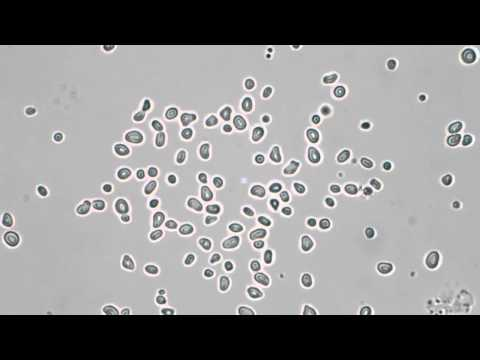

In [3]:
# или посмотреть с ютуба
from IPython.display import YouTubeVideo
YouTubeVideo('R5t-oA796to', width=600, height=300, start=11)

__Видео 1__: Видео броуновского движения, пример динамики Ланжевена, наблюдаемого экспериментально при наблюдении за пыльцевыми зернами в воде под микроскопом.

Теперь, когда вы понимаете, почему при моделировании динамики белка необходимо учитывать силы, возникающие при столкновении нашей системы с молекулами воды, давайте немного подробнее рассмотрим третий член уравнения Ланжевена, $\sqrt{2\gamma k_{B}T}R(t)$. Во-первых, отметим, что $k_B$ (постоянная Больцмана), $T$ (температура) и $\gamma$ (константа вязкости, о которой мы узнали выше) — константы, поэтому этот член представляет собой некоторую константу, умноженную на $R(t)$. Так что же такое $R(t)$? Функция $R(t)$ — это __стохастическая функция__, которая возвращает некоррелированные случайные числа из __гауссовского распределения__ со средним значением 0 и стандартным отклонением 1. По сути, случайные «толчки» системы берутся из стандартного гауссовского распределения (также известного как __нормальное распределение__) и умножаются на константу, которая растёт с ростом температуры. Таким образом, чем больше мы повышаем температуру, тем сильнее система подвергается случайным толчкам. Возвращаясь к пыльцевым зёрнам в воде, представленным выше, идея аналогична: вместо прямого моделирования большого количества молекул воды, отскакивающих от пыльцевых зёрен, мы просто определяем функцию, которая прикладывает случайные силы толчка к каждому пыльцевому зёрну.

Воспользуемся знаниями из прошлого урока, чтобы промоделировать ланжевеновскую динамику:

In [4]:
#setup the notebook
import numpy as np
import matplotlib.pyplot as plt

In [5]:
newParams = {'figure.figsize'  : (8, 8),  # Figure size
             'figure.dpi'      : 100,      # figure resolution
             'axes.titlesize'  : 18,       # fontsize of title
             'axes.labelsize'  : 14,       # fontsize of axes labels
             'axes.linewidth'  : 1,        # width of the figure box lines
             'lines.linewidth' : 2,        # width of the plotted lines
             'savefig.dpi'     : 200,      # resolution of a figured saved using plt.savefig(filename)
             'ytick.labelsize' : 14,       # fontsize of tick labels on y axis
             'xtick.labelsize' : 14,       # fontsize of tick labels on x axis
             'legend.fontsize' : 14,       # fontsize of labels in legend
             #'legend.title_fontsize' : 12,       # fontsize of labels in legend
             'legend.frameon'  : True,     # activate frame on lengend?
            }
plt.rcParams.update(newParams) # Set new plotting parameters

Задаем потенциал:

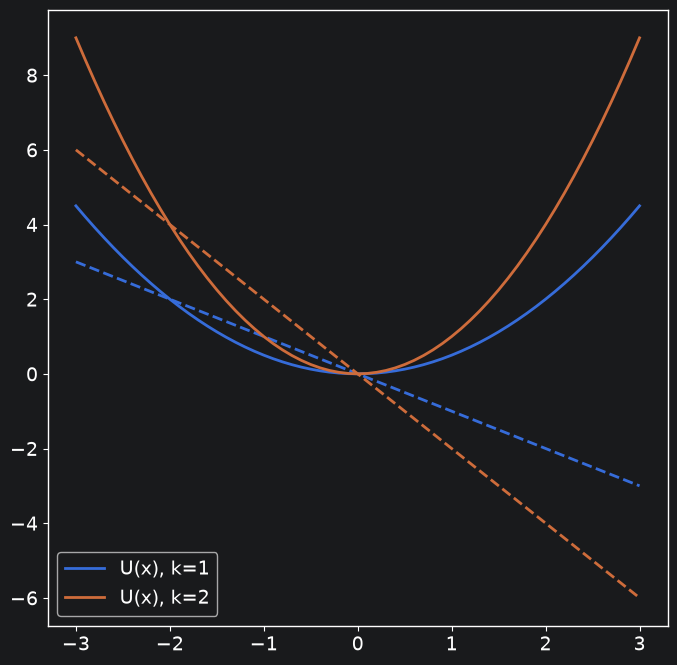

In [6]:
#this function returns the energy and force on a particle from a harmonic potential
def harmonic_oscillator_energy_force(x,k=1,x0=0):
    #calculate the energy on force on the right hand side of the equal signs
    energy = 0.5*k*(x-x0)**2
    force = -k*(x-x0)
    return energy, force

#this function will plot the energy and force
#it is very general since it uses a special python trick of taking arbitrary named arguments (**kwargs) 
#and passes them on to a specified input function
def plot_energy_force(function, xmin=-3,xmax=3,spacing=0.1,**kwargs):
    x_points = np.arange(xmin,xmax+spacing,spacing)
    energies, forces = function(x_points,**kwargs)
    label = 'U(x)'
    for arg in kwargs:
        label=label+', %s=%s'%(arg,str(kwargs[arg]))
    p = plt.plot(x_points,energies,label=label)
    plt.plot(x_points,forces,label='',color=p[0].get_color(),linestyle='--')
    plt.legend(loc=0)
    
#we can plot the energy (solid) and forces (dashed) to see if it looks right
plot_energy_force(harmonic_oscillator_energy_force,k=1)
plot_energy_force(harmonic_oscillator_energy_force,k=2)
plt.show()

Сейчас реализуем BAOAB-схему [Leimkuhler and Matthews (JCP, 2013)](https://sci-hub.ru/10.1063/1.4802990)

Следующие уравнения повторяются (выполнить b, a, o, a, b, затем повторить), чтобы двигаться вперед во времени. Шаги A и B представляют приращения на полушаг. 

**B:** $v(t) \leftarrow v(t) + \frac{F(t)}{m} (dt/2)$

**A:** $x(t) \leftarrow x(t) + v(t) (dt/2)$

Динамика системы задается уравнением:

$\frac{d v(t)}{dt} = - \gamma v dt + \sqrt{2 \gamma k_B T/m} d W$

($dW$ - случайная величина). Это частный случай уравнения Ланжевена.

Его решение приводит к правилу:

**O:** $v(t) \leftarrow e^{-\gamma dt} v(t) + R(t)\sqrt{k_B T/m} \sqrt{1-e^{-2\gamma dt}} $

где $R(t)$ является гауссовым случайным числом со средним нулевым и стандартным отклонением 1.

**Далее считаем, что масса $m = 1$**

In [7]:
#this is step A
def position_update(x,v,dt):
    x_new = x + v*dt/2.
    return x_new

#this is step B
def velocity_update(v,F,dt):
    v_new = v + F*dt/2.
    return v_new

def random_velocity_update(v,gamma,kBT,dt):
    R = np.random.normal()
    c1 = np.exp(-gamma*dt)
    c2 = np.sqrt(1-c1*c1)*np.sqrt(kBT)
    v_new = c1*v + R*c2
    return v_new


def baoab(potential, max_time, dt, gamma, kBT, initial_position, initial_velocity,
                                        save_frequency=3, **kwargs ):
    x = initial_position
    v = initial_velocity
    t = 0
    step_number = 0
    positions = []
    velocities = []
    total_energies = []
    save_times = []
    
    while(t<max_time):
        
        # B
        potential_energy, force = potential(x,**kwargs)
        v = velocity_update(v,force,dt)
        
        #A
        x = position_update(x,v,dt)

        #O
        v = random_velocity_update(v,gamma,kBT,dt)
        
        #A
        x = position_update(x,v,dt)
        
        # B
        potential_energy, force = potential(x,**kwargs)
        v = velocity_update(v,force,dt)
        
        if step_number%save_frequency == 0 and step_number>0:
            e_total = .5*v*v + potential_energy

            positions.append(x)
            velocities.append(v)
            total_energies.append(e_total)
            save_times.append(t)
        
        t = t+dt
        step_number = step_number + 1
    
    return save_times, positions, velocities, total_energies   

Пробуем для гармонического осциллятора (надо поиграться с параметрами):

In [8]:
my_k = 2
my_max_time = 100
initial_position = .1
initial_velocity = .5

my_gamma=0.1
my_kBT=0.25
my_dt=0.01

times, positions, velocities, total_energies = baoab(harmonic_oscillator_energy_force, 
                                                     my_max_time, my_dt, my_gamma, my_kBT, 
                                                     initial_position, initial_velocity,k=my_k)

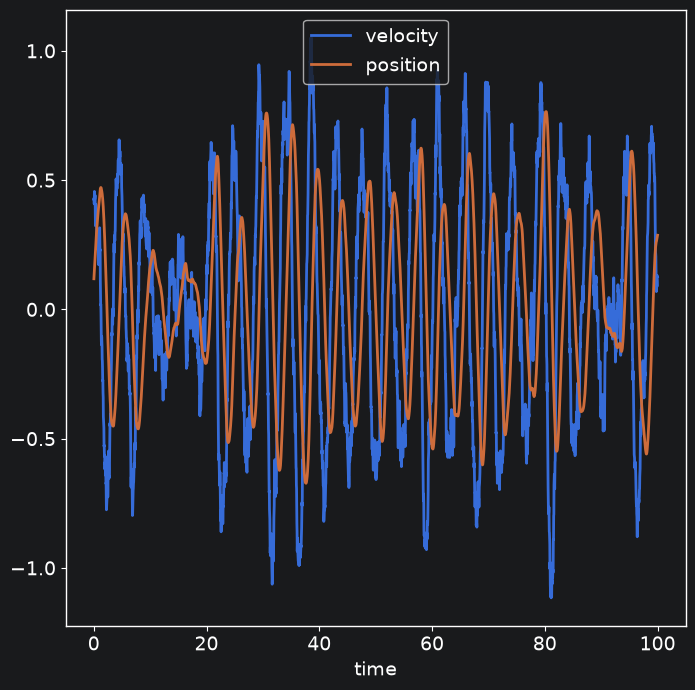

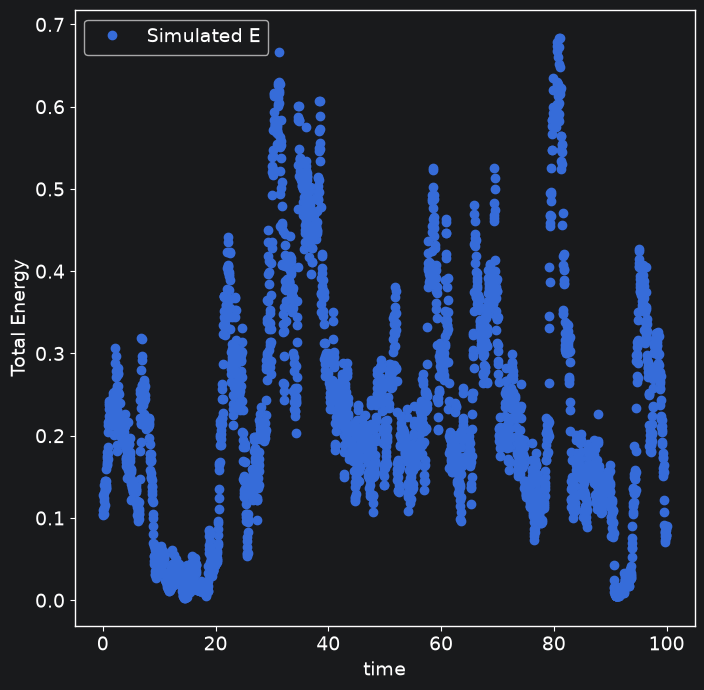

In [9]:
plt.plot(times,velocities,marker='',label='velocity',linestyle='-')
plt.plot(times,positions,marker='',label='position',linestyle='-')

plt.xlabel('time')
plt.legend(loc='upper center')

plt.figure()
plt.plot(times,total_energies,marker='o',linestyle='',label='Simulated E')
plt.xlabel('time')
plt.ylabel("Total Energy")
plt.legend()
plt.show()

Теперь мы имеем дело с каноническим распределением:

$P(x) = \frac{1}{\sqrt{2 \pi k_B T /k}} e^{-\frac{k (x-x_0)^2}{2 k_B T}}$

$P(v) = \frac{1}{\sqrt{2 \pi k_B T /m}} e^{-\frac{ m v^2}{2 k_B T}}$

$P(E) = e^{-E/k_B T}/\int e^{-E/k_B T} dE = \frac{1}{k_B T} e^{-E/k_B T}$

Гистограммы будут сравниваться с точными формулами.

In [10]:
def bin_centers(bin_edges):
    return (bin_edges[1:]+bin_edges[:-1])/2.

def gaussian_x(x,k,kBT):
    denominator = np.sqrt(2*np.pi*kBT/k)
    numerator = np.exp(-k*(x**2)/(2*kBT))
    return numerator/denominator

def gaussian_v(v,kBT):
    denominator = np.sqrt(2*np.pi*kBT)
    numerator = np.exp(-(v**2)/(2*kBT))
    return numerator/denominator

#to get a good histogram, we need to run a lot longer than before
my_max_time = 25000

times, positions, velocities, total_energies = baoab(harmonic_oscillator_energy_force, 
                                                     my_max_time, my_dt, my_gamma, my_kBT, 
                                                     initial_position, initial_velocity,k=my_k)

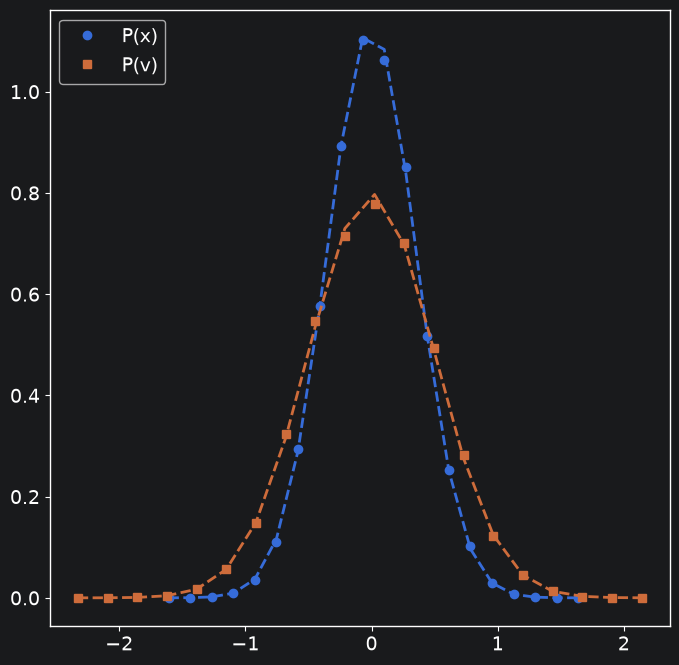

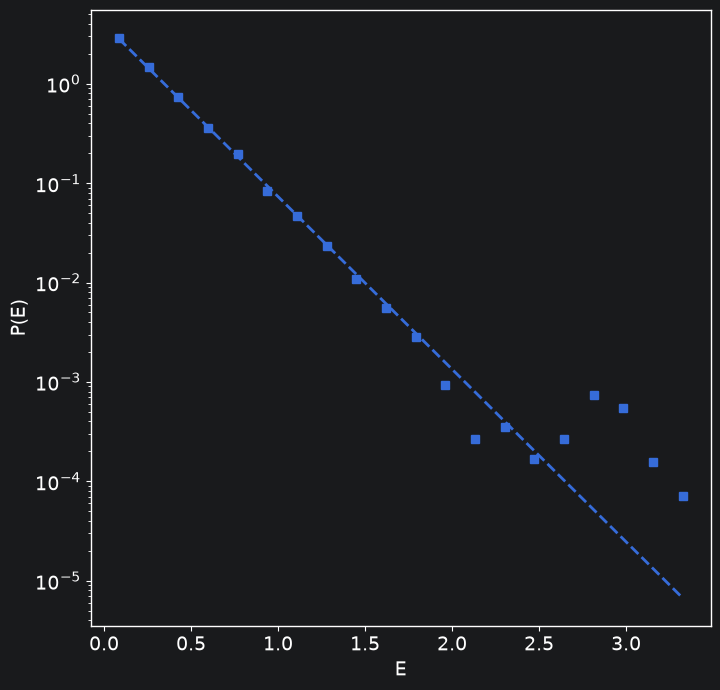

In [11]:
#let's only use data from the second half of the trajectory, so it can equilibrate
dist_hist, dist_bin_edges = np.histogram(positions[-len(positions)//2:],bins=20,density=True)
vel_hist, vel_bin_edges = np.histogram(velocities[-len(velocities)//2:],bins=20,density=True)
e_hist, e_bin_edges = np.histogram(total_energies[-len(total_energies)//2:],bins=20,density=True)


ideal_prediction_x = gaussian_x(x=bin_centers(dist_bin_edges),k=my_k,kBT=my_kBT )
p = plt.plot(bin_centers(dist_bin_edges), dist_hist,marker='o',label='P(x)',linestyle='')
plt.plot(bin_centers(dist_bin_edges), ideal_prediction_x,linestyle='--',label='', color=p[0].get_color())

ideal_prediction_v = gaussian_v(v=bin_centers(vel_bin_edges),kBT=my_kBT )
p = plt.plot(bin_centers(vel_bin_edges), vel_hist,marker='s',label='P(v)',linestyle='')
plt.plot(bin_centers(vel_bin_edges), ideal_prediction_v,linestyle='--',label='', color=p[0].get_color())

plt.legend(loc='upper left')

plt.figure()
p = plt.plot(bin_centers(e_bin_edges), e_hist,marker='s',label='P(E)',linestyle='')

#compute the energy histogram values to the boltzman factors for the observed energies
plt.plot(bin_centers(e_bin_edges), np.exp(-bin_centers(e_bin_edges)/my_kBT)/my_kBT,linestyle='--',color=p[0].get_color())
plt.yscale('log')
plt.xlabel("E")
plt.ylabel("P(E)")
plt.show()

## Двухямный потенциал ##

$U(x) = \frac{k}{4} (x-a)^2 (x+a)^2$

(-10.0, 10.0)

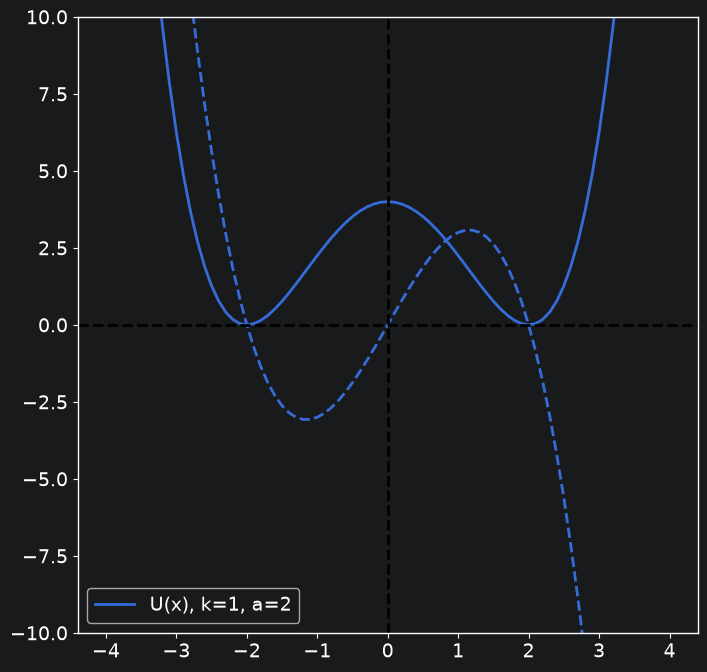

In [12]:
#this function returns the energy and force on a particle from a double well
def double_well_energy_force(x,k,a):
    #calculate the energy on force on the right hand side of the equal signs
    energy = 0.25*k*((x-a)**2) * ((x+a)**2)
    force = -k*x*(x-a)*(x+a)
    return energy, force

plot_energy_force(double_well_energy_force, xmin=-4,xmax=+4, k=1, a=2)
plt.axhline(0,linestyle='--',color='black')
plt.axvline(0,linestyle='--',color='black')
plt.ylim(-10,10)

### Ланжевеновская динамика схемой Верле в двухямном потенциале ###
Посмотрим, что произойдет, когда мы изменим температуру `my_kBt` и высоту барьера` my_a`.

1) Запустите симуляцию как есть, и увидите, что частица пробегает как левую, так и правую сторону ямы

2) Снизте температуру до 0.1, что произойдет?

3) Верните температуру на 1.0 и поднимите $ A $ до 3, что произойдет?

*Когда выборка эргодична?*

In [13]:
my_k = 1

#CHANGE THESE
my_kBT = 1.0
my_a = 2

my_initial_position = my_a
my_initial_velocity = 1

my_gamma = 0.1
my_dt = 0.05
my_max_time = 10000

times, positions, velocities, total_energies = baoab(double_well_energy_force, 
                                                     my_max_time, my_dt, my_gamma, my_kBT,
                                                     my_initial_position, my_initial_velocity,
                                                     k=my_k, a=my_a)

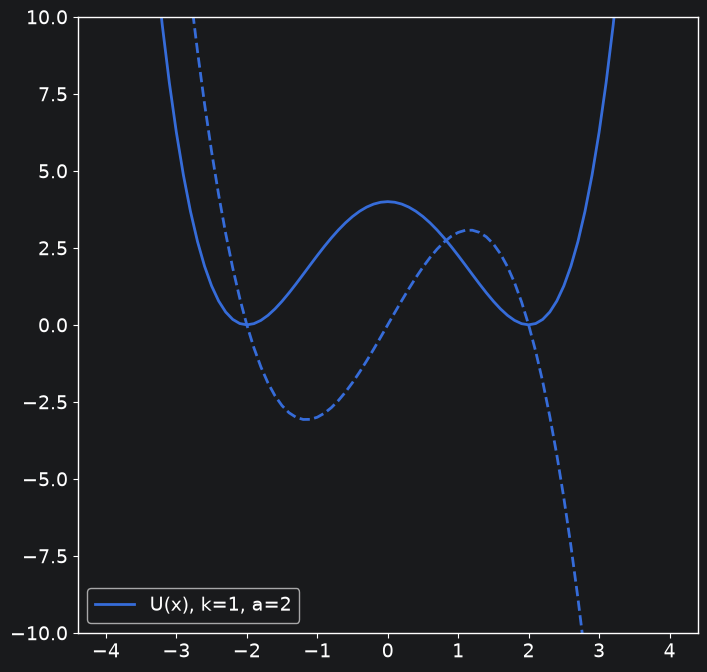

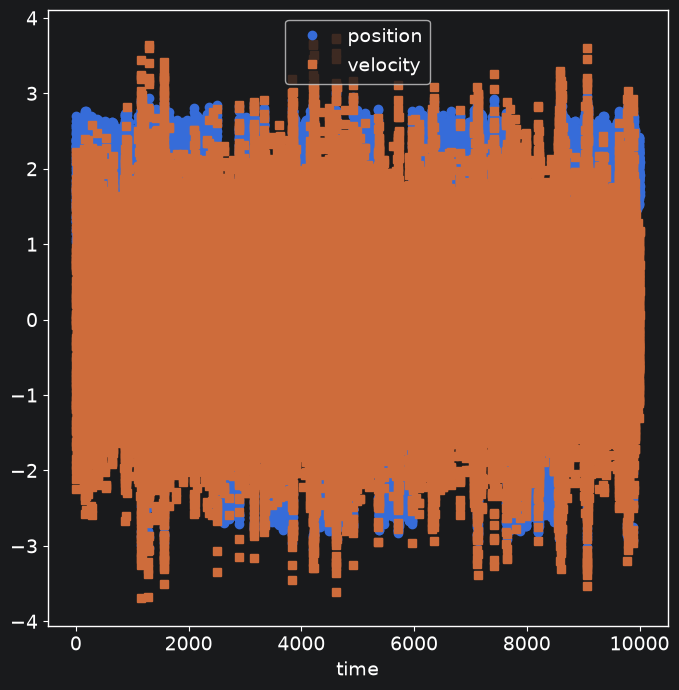

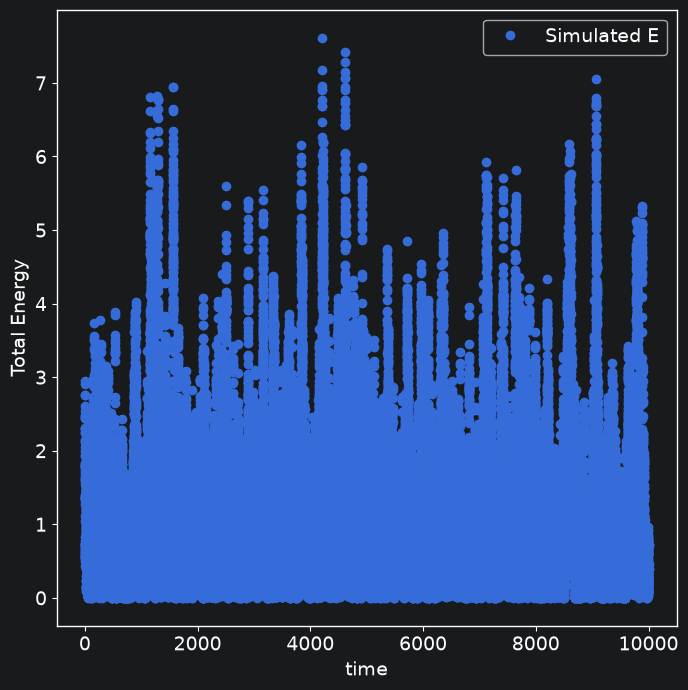

In [14]:
plot_energy_force(double_well_energy_force, xmin=-4,xmax=+4, k=my_k, a=my_a)
plt.ylim(-10,10)
plt.figure()

plt.plot(times,positions,marker='o',label='position',linestyle='')
plt.plot(times,velocities,marker='s',label='velocity',linestyle='')
plt.xlabel('time')
plt.legend(loc='upper center')

plt.figure()
initial_energy = total_energies[0]
plt.plot(times,total_energies,marker='o',linestyle='',label='Simulated E')
plt.xlabel('time')
plt.ylabel("Total Energy")
plt.legend()

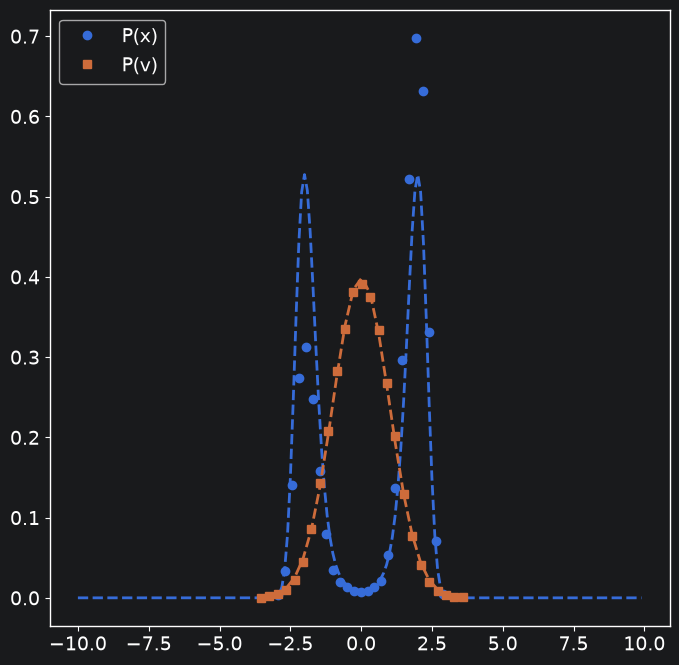

In [15]:
# histogramming the results
plt.figure()
dist_hist, dist_bin_edges = np.histogram(positions,bins=25,density=True)
vel_hist, vel_bin_edges = np.histogram(velocities,bins=25,density=True)

p = plt.plot(bin_centers(dist_bin_edges), dist_hist,marker='o',label='P(x)',linestyle='')

#test against exact prediction
dd = 0.1
test_bin_positions = np.arange(-10,10,dd)
double_well_energies, double_well_froces = double_well_energy_force(test_bin_positions,my_k,my_a)

plt.plot(test_bin_positions, np.exp(-double_well_energies/my_kBT)/np.sum(dd*np.exp(-double_well_energies/my_kBT)),\
     linestyle='--',color=p[0].get_color())

p = plt.plot(bin_centers(vel_bin_edges), vel_hist,marker='s',label='P(v)',linestyle='')
ideal_prediction_v = gaussian_v(v=bin_centers(vel_bin_edges),kBT=my_kBT )
plt.plot(bin_centers(vel_bin_edges), ideal_prediction_v,linestyle='--',label='', color=p[0].get_color())

plt.legend(loc='upper left')

kBT=1.0, a=2: переходов 68, доля x<0: 0.416
kBT=0.1, a=2: переходов 0, доля x<0: 0.000
kBT=1.0, a=3: переходов 0, доля x<0: 0.000


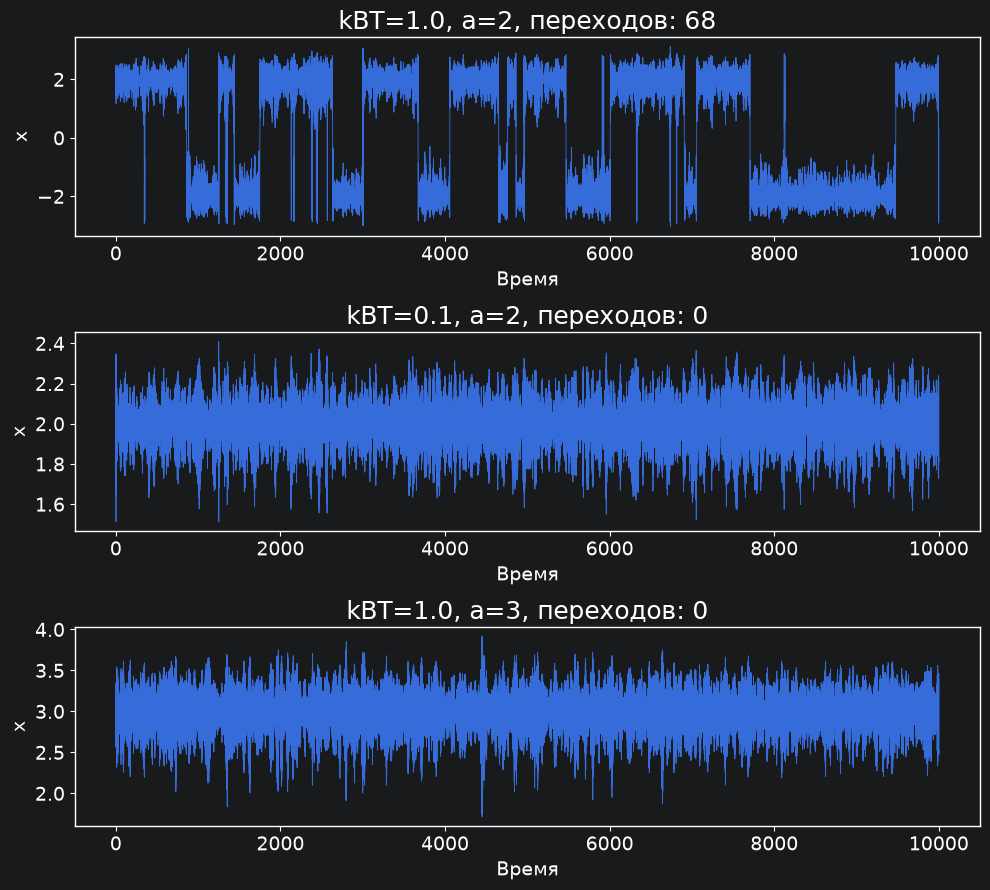

In [16]:
# При kBT=1 и a=2 частица переходит между ямами.
# При kBT=0.1 переходы подавлены; при a=3 барьер k*a**4/4 выше.
# Выборка эргодична на наблюдаемом времени, если многократно посещаются обе ямы.
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
for ax, (temperature, a_value) in zip(axes, [(1.0, 2), (0.1, 2), (1.0, 3)]):
    np.random.seed(42)
    t, x, v, energies = baoab(double_well_energy_force, 10000, 0.05, 0.1, temperature, a_value, 1, k=1, a=a_value)
    x = np.asarray(x)
    transitions = np.count_nonzero(np.diff(np.sign(x)))
    ax.plot(t, x, linewidth=0.6)
    ax.set(title=f'kBT={temperature}, a={a_value}, переходов: {transitions}', xlabel='Время', ylabel='x')
    print(f'kBT={temperature}, a={a_value}: переходов {transitions}, доля x<0: {np.mean(x < 0):.3f}')
plt.tight_layout()
plt.show()